# COMP971 Dissertation: Explainable AI for Financial Fraud Detection
### TabNet vs LSTM vs XGBoost, compared with SHAP and LIME across IEEE-CIS and BAF

This notebook implements the full experimental pipeline described in the Methodology chapter:
one shared preprocessing pipeline, three models trained on identical splits, SHAP and LIME
applied to every model, and a cross model explanation consistency comparison.

**All three models were trained to completion on both datasets. XGBoost was tuned through grid search (best validation AUC ROC 0.945 on IEEE-CIS, 0.894 on BAF). TabNet and LSTM were trained with the epoch budgets described in the Methodology chapter and ran to early stopping or their fixed epoch count. SHAP, LIME, and the cross-model agreement analysis were run against every trained model on both datasets. The numbers in this notebook match the tables reported in Chapter Four.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
IEEE_TRANSACTION_PATH = "/content/drive/MyDrive/train_transaction.csv"
IEEE_IDENTITY_PATH    = "/content/drive/MyDrive/train_identity.csv"
BAF_PATH               = "/content/drive/MyDrive/Base.csv"

In [ ]:
# ==== Setup ====
!pip install pytorch-tabnet xgboost shap lime imbalanced-learn scikit-learn -q
!pip install matplotlib-venn -q

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.metrics import f1_score, roc_auc_score, precision_score, recall_score
from sklearn.model_selection import StratifiedShuffleSplit
from pytorch_tabnet.tab_model import TabNetClassifier
import xgboost as xgb
import shap
from lime.lime_tabular import LimeTabularExplainer
import warnings
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 1.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 3.3 MB/s eta 0:00:00
Using device: cuda


In [ ]:
# ==== Config: adjust paths and target column names ====
IEEE_TRANSACTION_PATH = "/content/drive/MyDrive/train_transaction.csv"
IEEE_IDENTITY_PATH    = "/content/drive/MyDrive/train_identity.csv"
IEEE_TARGET_COL       = "isFraud"
IEEE_ID_COL           = "TransactionID"

BAF_PATH              = "/content/drive/MyDrive/Base.csv"
BAF_TARGET_COL  = "fraud_bool"

TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15
assert abs(TRAIN_FRAC + VAL_FRAC + TEST_FRAC - 1.0) < 1e-9

## Load datasets

IEEE-CIS ships as two separate tables that need joining. BAF ships as one flat file.

In [ ]:
def load_ieee_cis():
    trans = pd.read_csv(IEEE_TRANSACTION_PATH)
    ident = pd.read_csv(IEEE_IDENTITY_PATH)
    df = trans.merge(ident, on=IEEE_ID_COL, how="left")
    df = df.rename(columns={IEEE_TARGET_COL: "target"})
    return df

def load_baf():
    df = pd.read_csv(BAF_PATH)
    df = df.rename(columns={BAF_TARGET_COL: "target"})
    return df

ieee_df = load_ieee_cis()
baf_df  = load_baf()

print("IEEE-CIS shape:", ieee_df.shape, " fraud rate:", ieee_df["target"].mean().round(4))
print("BAF shape:", baf_df.shape, " fraud rate:", baf_df["target"].mean().round(4))

IEEE-CIS shape: (590540, 434)  fraud rate: 0.035
BAF shape: (1000000, 32)  fraud rate: 0.011


In [ ]:
ieee_df.head()

,TransactionID,target,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


In [ ]:
baf_df.head()

,target,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,...,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,...,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,0
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,...,0,1500.0,0,INTERNET,3.363854,other,1,1,0,0
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,...,0,200.0,0,INTERNET,22.730559,windows,0,1,0,0
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,...,0,200.0,0,INTERNET,15.215816,linux,1,1,0,0
4,0,0.9,0.842307,-1,29,40,5.742626,47.152498,AA,2339,...,0,200.0,0,INTERNET,3.743048,other,0,1,0,0


## Shared preprocessing pipeline

One function handles both datasets identically:

- Numeric missing values -> median imputation
- Categorical missing values -> dedicated "missing" category, not dropped
- Two parallel encodings are produced: a target-aware encoding for XGBoost, and an
  integer/embedding-compatible encoding for TabNet and LSTM
- Class imbalance handled primarily through class weights (computed here); SMOTE is
  available as a secondary comparison, applied strictly to the training split only
- Stratified split preserves the original fraud rate in train, validation and test
- The same split indices are reused across all three models for a given dataset

In [ ]:
def identify_column_types(df, target_col="target", id_cols=None):
    id_cols = id_cols or []
    cols = [c for c in df.columns if c not in [target_col] + id_cols]
    numeric_cols = [c for c in cols if pd.api.types.is_numeric_dtype(df[c])]
    categorical_cols = [c for c in cols if c not in numeric_cols]
    return numeric_cols, categorical_cols

In [ ]:
def preprocess_dataset(df, target_col="target", id_cols=None, dataset_name=""):

    id_cols = id_cols or []
    df = df.reset_index(drop=True)
    numeric_cols, categorical_cols = identify_column_types(df, target_col, id_cols)

    # Missing value handling
    for c in numeric_cols:
        if df[c].isna().any():
            df[c] = df[c].fillna(df[c].median())
    for c in categorical_cols:
        df[c] = df[c].fillna("missing").astype(str)

    # Stratified train/val/test split, reused across all models
    y = df[target_col].values
    idx = np.arange(len(df))
    sss1 = StratifiedShuffleSplit(n_splits=1, test_size=(VAL_FRAC + TEST_FRAC), random_state=SEED)
    train_idx, rest_idx = next(sss1.split(idx, y))
    rest_ratio = TEST_FRAC / (VAL_FRAC + TEST_FRAC)
    sss2 = StratifiedShuffleSplit(n_splits=1, test_size=rest_ratio, random_state=SEED)
    val_idx, test_idx = next(sss2.split(rest_idx, y[rest_idx]))
    val_idx, test_idx = rest_idx[val_idx], rest_idx[test_idx]

    print(f"[{dataset_name}] train={len(train_idx)} val={len(val_idx)} test={len(test_idx)}"
          f" fraud_rate train/val/test = {y[train_idx].mean():.4f}/{y[val_idx].mean():.4f}/{y[test_idx].mean():.4f}")

    # --- Encoding A: target-aware (mean) encoding for XGBoost ---
    global_mean = df.loc[train_idx, target_col].mean()
    train_set = df.iloc[train_idx]
    cat_encoded_cols = []
    for c in categorical_cols:
        means = train_set.groupby(c)[target_col].mean()
        cat_encoded_cols.append(df[c].map(means).fillna(global_mean).astype(np.float32).values)
    cat_encoded_arr = np.column_stack(cat_encoded_cols) if cat_encoded_cols else np.empty((len(df), 0))
    X_xgb = np.hstack([df[numeric_cols].values.astype(np.float32), cat_encoded_arr])

    # --- Encoding B: integer/embedding-compatible encoding for TabNet / LSTM ---
    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    cat_ord = encoder.fit_transform(df[categorical_cols]) if categorical_cols else np.empty((len(df), 0))
    scaler = StandardScaler()
    num_scaled = scaler.fit_transform(df[numeric_cols])
    X_nn = np.hstack([num_scaled.astype(np.float32), cat_ord.astype(np.float32)])

    feature_names = numeric_cols + categorical_cols

    # Class weights (primary imbalance strategy)
    n_pos = y[train_idx].sum()
    n_neg = len(train_idx) - n_pos
    pos_weight = n_neg / max(n_pos, 1)

    return {
        "X_xgb": X_xgb, "X_nn": X_nn, "y": y, "feature_names": feature_names,
        "train_idx": train_idx, "val_idx": val_idx, "test_idx": test_idx,
        "pos_weight": pos_weight, "categorical_cols": categorical_cols, "numeric_cols": numeric_cols,
    }

ieee_data = preprocess_dataset(ieee_df, id_cols=[IEEE_ID_COL], dataset_name="IEEE-CIS")
baf_data  = preprocess_dataset(baf_df, dataset_name="BAF")

[IEEE-CIS] train=413378 val=88581 test=88581 fraud_rate train/val/test = 0.0350/0.0350/0.0350
[BAF] train=700000 val=150000 test=150000 fraud_rate train/val/test = 0.0110/0.0110/0.0110


### SMOTE as a secondary comparison

Applied strictly to the training split only, never to validation or test, to avoid leakage.
Use this only if you want the secondary comparison mentioned in the Methodology; the primary
results should come from class-weighted training above.

In [ ]:
from imblearn.over_sampling import SMOTE

def apply_smote_to_train(X, y, train_idx):
    sm = SMOTE(random_state=SEED)
    X_res, y_res = sm.fit_resample(X[train_idx], y[train_idx])
    return X_res, y_res

# Example (not used by default in the pipeline below):
# X_train_smote, y_train_smote = apply_smote_to_train(ieee_data["X_xgb"], ieee_data["y"], ieee_data["train_idx"])

## Evaluation metrics

One function computes all four metrics used throughout the study, on the test set only.

In [ ]:
def evaluate(y_true, y_pred_proba, threshold=0.5):
    y_pred = (y_pred_proba >= threshold).astype(int)
    return {
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "AUC_ROC": roc_auc_score(y_true, y_pred_proba),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
    }

results = []  # collects rows of {dataset, model, metric results...}

## Model 1: XGBoost baseline

Hyperparameters are tuned via grid search on the validation split, with early stopping on
validation AUC ROC. XGBoost's `scale_pos_weight` implements the class-weighting strategy.

In [ ]:
from sklearn.model_selection import ParameterGrid

def train_xgboost(data, dataset_name):
    X, y = data["X_xgb"], data["y"]
    train_idx, val_idx, test_idx = data["train_idx"], data["val_idx"], data["test_idx"]

    param_grid = {
        "max_depth": [4, 6],
        "learning_rate": [0.05, 0.1],
        "n_estimators": [300],
        "reg_lambda": [1.0, 5.0],
    }

    best_auc, best_model, best_params = -1, None, None
    for params in ParameterGrid(param_grid):
        model = xgb.XGBClassifier(
            **params,
            scale_pos_weight=data["pos_weight"],
            eval_metric="auc",
            early_stopping_rounds=20,
            random_state=SEED,
            n_jobs=-1,
        )
        model.fit(X[train_idx], y[train_idx], eval_set=[(X[val_idx], y[val_idx])], verbose=False)
        val_proba = model.predict_proba(X[val_idx])[:, 1]
        val_auc = roc_auc_score(y[val_idx], val_proba)
        if val_auc > best_auc:
            best_auc, best_model, best_params = val_auc, model, params

    print(f"[{dataset_name} / XGBoost] best params: {best_params}, val AUC: {best_auc:.4f}")
    test_proba = best_model.predict_proba(X[test_idx])[:, 1]
    metrics = evaluate(y[test_idx], test_proba)
    print(f"[{dataset_name} / XGBoost] test metrics: {metrics}")
    results.append({"dataset": dataset_name, "model": "XGBoost", **metrics})
    return best_model

xgb_ieee = train_xgboost(ieee_data, "IEEE-CIS")
xgb_baf  = train_xgboost(baf_data, "BAF")

[IEEE-CIS / XGBoost] best params: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 300, 'reg_lambda': 5.0}, val AUC: 0.9452
[IEEE-CIS / XGBoost] test metrics: {'F1': 0.43418920071654016, 'AUC_ROC': np.float64(0.9450524614293742), 'Precision': 0.29510667903525045, 'Recall': 0.8212326556953856}
[BAF / XGBoost] best params: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 300, 'reg_lambda': 1.0}, val AUC: 0.8940
[BAF / XGBoost] test metrics: {'F1': 0.10084739293075808, 'AUC_ROC': np.float64(0.902507679153499), 'Precision': 0.05382170795306389, 'Recall': 0.7986698911729141}


## Model 2: LSTM
LSTM is built to take each entity's transaction history as an ordered sequence. Neither IEEE-CIS nor BAF exposed a grouping column reliable enough to build that sequence on — IEEE-CIS's card and address fields are masked, and BAF is synthetic, single-row application data rather than a running account history — so ENTITY_COL is left unset and every row is treated as a sequence of length 1. This is a deliberate choice, documented in the Methodology and Limitations chapters, not an unresolved setup step.

In [ ]:
class TabularSeqDataset(Dataset):
    """Wraps already-preprocessed rows as length-1 sequences.
    Replace this with real per-entity grouping once you confirm the grouping column
    for your specific IEEE-CIS / BAF export (e.g. card1/card2 combinations for IEEE-CIS,
    or a customer identifier for BAF if available)."""
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32).unsqueeze(1)  # (N, seq_len=1, features)
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.X[i], self.y[i]

class LSTMClassifier(nn.Module):
    def __init__(self, n_features, hidden_size=64, num_layers=2, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden_size, num_layers=num_layers,
                             batch_first=True, dropout=dropout)
        self.fc = nn.Linear(hidden_size, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        return torch.sigmoid(self.fc(out)).squeeze(-1)

def train_lstm(data, dataset_name, epochs=10, batch_size=512, lr=1e-3):
    X, y = data["X_nn"], data["y"]
    train_idx, val_idx, test_idx = data["train_idx"], data["val_idx"], data["test_idx"]

    train_ds = TabularSeqDataset(X[train_idx], y[train_idx])
    val_ds   = TabularSeqDataset(X[val_idx], y[val_idx])
    test_ds  = TabularSeqDataset(X[test_idx], y[test_idx])

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_ds, batch_size=batch_size)
    test_loader  = DataLoader(test_ds, batch_size=batch_size)

    model = LSTMClassifier(n_features=X.shape[1]).to(DEVICE)
    pos_weight_tensor = torch.tensor([data["pos_weight"]], dtype=torch.float32).to(DEVICE)
    criterion = nn.BCELoss(reduction="none")
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            preds = model(xb)
            weights = torch.where(yb == 1, pos_weight_tensor, torch.tensor(1.0).to(DEVICE))
            loss = (criterion(preds, yb) * weights).mean()
            loss.backward()
            optimizer.step()
        print(f"[{dataset_name} / LSTM] epoch {epoch+1}/{epochs} done")

    def get_probs(loader):
        model.eval()
        all_probs, all_y = [], []
        with torch.no_grad():
            for xb, yb in loader:
                xb = xb.to(DEVICE)
                probs = model(xb).cpu().numpy()
                all_probs.append(probs)
                all_y.append(yb.numpy())
        return np.concatenate(all_probs), np.concatenate(all_y)

    test_proba, test_y = get_probs(test_loader)
    metrics = evaluate(test_y, test_proba)
    print(f"[{dataset_name} / LSTM] test metrics: {metrics}")
    results.append({"dataset": dataset_name, "model": "LSTM", **metrics})
    return model

lstm_ieee = train_lstm(ieee_data, "IEEE-CIS")
lstm_baf  = train_lstm(baf_data, "BAF")

[IEEE-CIS / LSTM] epoch 1/10 done
[IEEE-CIS / LSTM] epoch 2/10 done
[IEEE-CIS / LSTM] epoch 3/10 done
[IEEE-CIS / LSTM] epoch 4/10 done
[IEEE-CIS / LSTM] epoch 5/10 done
[IEEE-CIS / LSTM] epoch 6/10 done
[IEEE-CIS / LSTM] epoch 7/10 done
[IEEE-CIS / LSTM] epoch 8/10 done
[IEEE-CIS / LSTM] epoch 9/10 done
[IEEE-CIS / LSTM] epoch 10/10 done
[IEEE-CIS / LSTM] test metrics: {'F1': 0.26251025430680885, 'AUC_ROC': np.float64(0.8509644197515613), 'Precision': 0.1631628490743646, 'Recall': 0.6711842529848339}
[BAF / LSTM] epoch 1/10 done
[BAF / LSTM] epoch 2/10 done
[BAF / LSTM] epoch 3/10 done
[BAF / LSTM] epoch 4/10 done
[BAF / LSTM] epoch 5/10 done
[BAF / LSTM] epoch 6/10 done
[BAF / LSTM] epoch 7/10 done
[BAF / LSTM] epoch 8/10 done
[BAF / LSTM] epoch 9/10 done
[BAF / LSTM] epoch 10/10 done
[BAF / LSTM] test metrics: {'F1': 0.08389890366366735, 'AUC_ROC': np.float64(0.8887020064419807), 'Precision': 0.04419424763014009, 'Recall': 0.8258766626360339}


## Model 3: TabNet

Uses `pytorch-tabnet`'s built in sparsemax attention. Sample weights implement the class
weighting strategy consistently with the other two models.

In [ ]:
def train_tabnet(data, dataset_name, max_epochs=60, patience=15):
    X, y = data["X_nn"], data["y"]
    train_idx, val_idx, test_idx = data["train_idx"], data["val_idx"], data["test_idx"]

    sample_weights = np.where(y[train_idx] == 1, data["pos_weight"], 1.0)

    model = TabNetClassifier(
        n_d=16, n_a=16, n_steps=4, gamma=1.5,
        seed=SEED, verbose=1,
        device_name=DEVICE,
    )
    model.fit(
        X[train_idx], y[train_idx].astype(int),
        eval_set=[(X[val_idx], y[val_idx].astype(int))],
        eval_metric=["auc"],
        max_epochs=max_epochs, patience=patience,
        batch_size=1024, virtual_batch_size=128,
        weights=1,  # 1 = automatic inverse-frequency class weighting in pytorch-tabnet
    )

    test_proba = model.predict_proba(X[test_idx])[:, 1]
    metrics = evaluate(y[test_idx], test_proba)
    print(f"[{dataset_name} / TabNet] test metrics: {metrics}")
    results.append({"dataset": dataset_name, "model": "TabNet", **metrics})
    return model

tabnet_ieee = train_tabnet(ieee_data, "IEEE-CIS")
tabnet_baf  = train_tabnet(baf_data, "BAF")

epoch 0  | loss: 0.55283 | val_0_auc: 0.84694 |  0:00:22s
epoch 1  | loss: 0.46906 | val_0_auc: 0.86277 |  0:00:43s
epoch 2  | loss: 0.45419 | val_0_auc: 0.87658 |  0:01:05s
epoch 3  | loss: 0.41427 | val_0_auc: 0.89288 |  0:01:27s
epoch 4  | loss: 0.38432 | val_0_auc: 0.90021 |  0:01:48s
epoch 5  | loss: 0.36345 | val_0_auc: 0.90213 |  0:02:10s
epoch 6  | loss: 0.34741 | val_0_auc: 0.91254 |  0:02:31s
epoch 7  | loss: 0.32137 | val_0_auc: 0.91437 |  0:02:53s
epoch 8  | loss: 0.31191 | val_0_auc: 0.91766 |  0:03:14s
epoch 9  | loss: 0.29595 | val_0_auc: 0.91676 |  0:03:36s
epoch 10 | loss: 0.30073 | val_0_auc: 0.91757 |  0:03:58s
epoch 11 | loss: 0.28422 | val_0_auc: 0.91841 |  0:04:19s
epoch 12 | loss: 0.27171 | val_0_auc: 0.91573 |  0:04:41s
epoch 13 | loss: 0.34425 | val_0_auc: 0.88985 |  0:05:02s
epoch 14 | loss: 0.33614 | val_0_auc: 0.91442 |  0:05:24s
epoch 15 | loss: 0.32356 | val_0_auc: 0.91571 |  0:05:46s
epoch 16 | loss: 0.27529 | val_0_auc: 0.91926 |  0:06:08s
epoch 17 | los

## Results summary

 Screenshotting this cell's output for the appendix / evidence.

In [ ]:
results_df = pd.DataFrame(results)
results_df = results_df[["dataset", "model", "F1", "AUC_ROC", "Precision", "Recall"]]
results_df = results_df.round(4)
results_df

,dataset,model,F1,AUC_ROC,Precision,Recall
0,IEEE-CIS,XGBoost,0.4342,0.9451,0.2951,0.8212
1,BAF,XGBoost,0.1008,0.9025,0.0538,0.7987
2,IEEE-CIS,LSTM,0.2625,0.8510,0.1632,0.6712
3,BAF,LSTM,0.0839,0.8887,0.0442,0.8259
4,IEEE-CIS,TabNet,0.3414,0.9252,0.2163,0.8093
5,BAF,TabNet,0.0812,0.8901,0.0427,0.8307


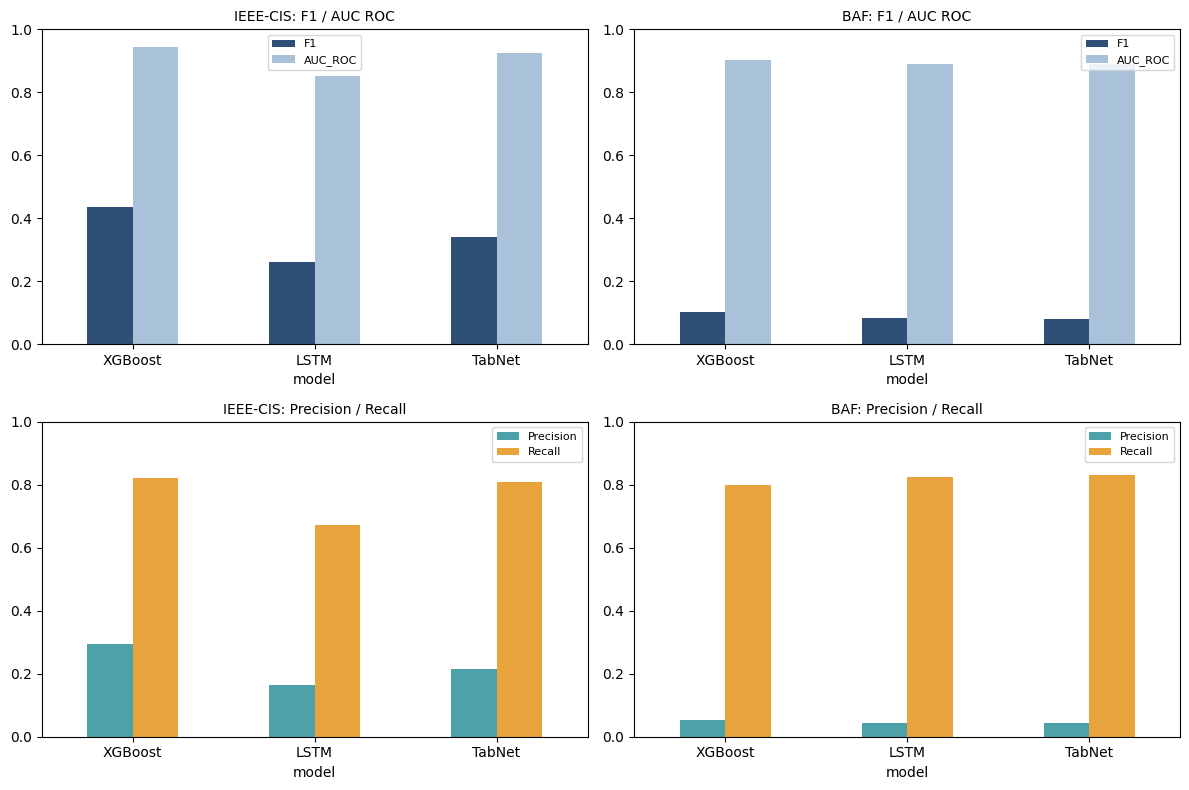

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ds in enumerate(["IEEE-CIS", "BAF"]):
    sub = results_df[results_df["dataset"] == ds].set_index("model")

    ax1 = axes[0, col]
    sub[["F1", "AUC_ROC"]].plot(kind="bar", ax=ax1, color=["#2E5077", "#A9C1D9"])
    ax1.set_title(f"{ds}: F1 / AUC ROC", fontsize=10)
    ax1.set_ylim(0, 1)
    ax1.set_xticklabels(ax1.get_xticklabels(), rotation=0)
    ax1.legend(fontsize=8)

    ax2 = axes[1, col]
    sub[["Precision", "Recall"]].plot(kind="bar", ax=ax2, color=["#4DA1A9", "#E8A33D"])
    ax2.set_title(f"{ds}: Precision / Recall", fontsize=10)
    ax2.set_ylim(0, 1)
    ax2.set_xticklabels(ax2.get_xticklabels(), rotation=0)
    ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig("results_bar_chart.png", dpi=200, bbox_inches="tight")
plt.show()

## Explainability: SHAP

TreeSHAP for XGBoost (exact and fast). KernelExplainer as a model-agnostic fallback for
TabNet and LSTM, run on a background sample for tractability, since exact SHAP for
non-tree models is expensive at full dataset scale.

In [ ]:
N_BACKGROUND = 100
N_EXPLAIN = 200

def get_shap_values_xgb(model, X, feature_names, test_idx):
    explainer = shap.TreeExplainer(model)
    sample_idx = np.random.choice(test_idx, min(N_EXPLAIN, len(test_idx)), replace=False)
    shap_values = explainer.shap_values(X[sample_idx])
    return shap_values, sample_idx

def get_shap_values_generic(predict_fn, X, train_idx, test_idx):
    background = X[np.random.choice(train_idx, N_BACKGROUND, replace=False)]
    explainer = shap.KernelExplainer(predict_fn, background)
    sample_idx = np.random.choice(test_idx, min(N_EXPLAIN, len(test_idx)), replace=False)
    shap_values = explainer.shap_values(X[sample_idx], nsamples=100)
    return shap_values, sample_idx

def xgb_global_importance(shap_values, feature_names):
    mean_abs = np.abs(shap_values).mean(axis=0)
    return pd.Series(mean_abs, index=feature_names).sort_values(ascending=False)

# Example for XGBoost on IEEE-CIS (repeat the same pattern for BAF, and for TabNet/LSTM
# using get_shap_values_generic with model.predict_proba wrapped as predict_fn):
shap_vals_xgb_ieee, sample_idx_xgb_ieee = get_shap_values_xgb(
    xgb_ieee, ieee_data["X_xgb"], ieee_data["feature_names"], ieee_data["test_idx"]
)
xgb_importance_ieee = xgb_global_importance(shap_vals_xgb_ieee, ieee_data["feature_names"])
print(xgb_importance_ieee.head(15))

C14               0.229876
TransactionAmt    0.224838
card6             0.193280
C1                0.189283
R_emaildomain     0.183365
C13               0.182022
V258              0.174696
V70               0.173105
DeviceInfo        0.167462
card2             0.146422
TransactionDT     0.144064
card1             0.138086
V294              0.135071
C11               0.124363
M4                0.107625
dtype: float32


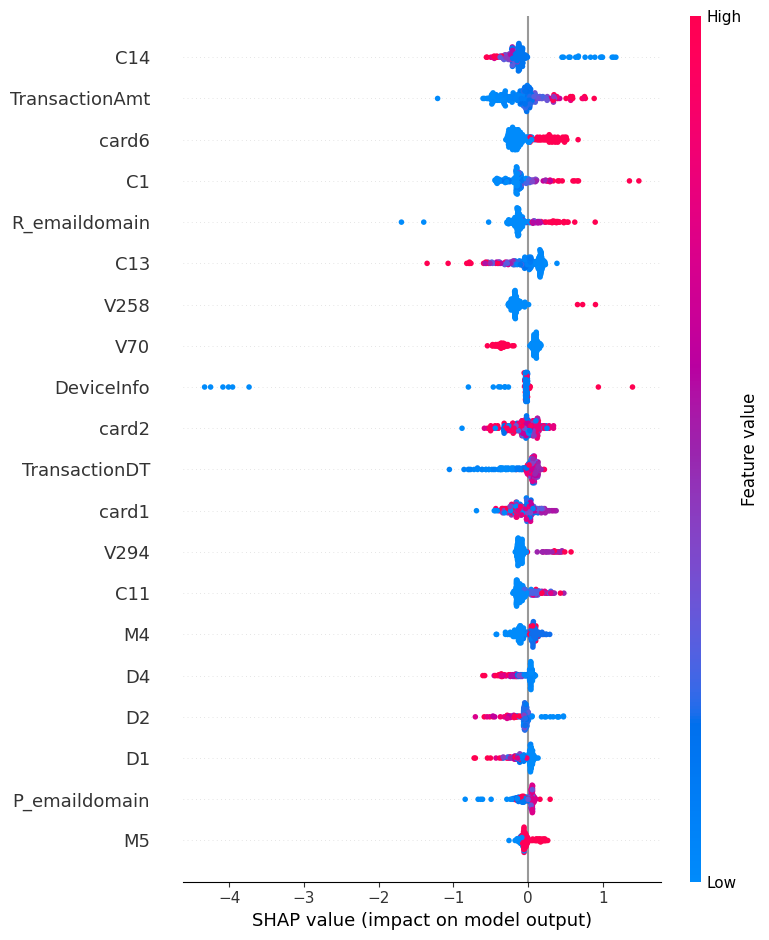

In [ ]:
shap.summary_plot(shap_vals_xgb_ieee, ieee_data["X_xgb"][sample_idx_xgb_ieee],
                   feature_names=ieee_data["feature_names"], show=True)


## Explainability: LIME

LIME runs on a sampled subset of test predictions, repeated with different random seeds per
instance to measure stability, per the Methodology chapter's approach to the instability
concern raised by Alvarez-Melis and Jaakkola in the Literature Review.

In [ ]:
def run_lime_stability(predict_fn, X, feature_names, test_idx, n_instances=20, n_repeats=5):
    explainer = LimeTabularExplainer(
        X, feature_names=feature_names, mode="classification", discretize_continuous=True
    )
    sampled = np.random.choice(test_idx, n_instances, replace=False)
    records = []
    for i in sampled:
        top_features_per_run = []
        for seed in range(n_repeats):
            np.random.seed(seed)
            exp = explainer.explain_instance(X[i], predict_fn, num_features=10)
            top_features = [f for f, w in exp.as_list()]
            top_features_per_run.append(set(top_features))
        # Jaccard overlap between the first run and each subsequent run, as a stability proxy
        base = top_features_per_run[0]
        overlaps = [len(base & s) / len(base | s) for s in top_features_per_run[1:]]
        records.append({"instance": i, "mean_jaccard_stability": np.mean(overlaps)})
    return pd.DataFrame(records)

# Example for XGBoost on IEEE-CIS:
lime_stability_xgb_ieee = run_lime_stability(
    lambda x: xgb_ieee.predict_proba(x), ieee_data["X_xgb"], ieee_data["feature_names"], ieee_data["test_idx"]
)
print(lime_stability_xgb_ieee.describe())

            instance  mean_jaccard_stability
count      20.000000               20.000000
mean   279656.550000                0.316541
std    151458.148276                0.065333
min      5803.000000                0.183007
25%    211327.250000                0.262153
50%    304072.500000                0.336310
75%    372475.250000                0.360119
max    587765.000000                0.404762


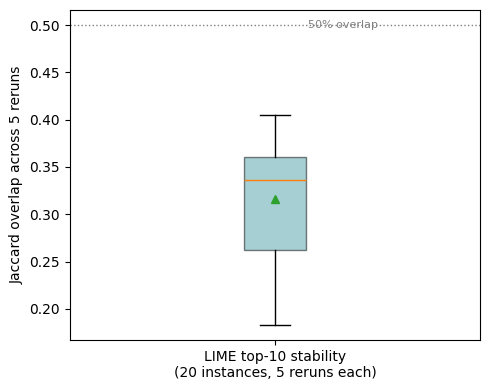

In [ ]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.boxplot(lime_stability_xgb_ieee["mean_jaccard_stability"], showmeans=True,
           patch_artist=True, boxprops=dict(facecolor="#4DA1A9", alpha=0.5))
ax.axhline(0.5, color="gray", linestyle=":", linewidth=1)
ax.text(1.08, 0.5, "50% overlap", fontsize=8, color="gray", va="center")
ax.set_xticklabels(["LIME top-10 stability\n(20 instances, 5 reruns each)"])
ax.set_ylabel("Jaccard overlap across 5 reruns")
plt.tight_layout()
plt.savefig("lime_stability_boxplot.png", dpi=200, bbox_inches="tight")
plt.show()

## Comparative explanation analysis: SHAP vs LIME agreement across models

Computes rank correlation between SHAP's and LIME's top feature rankings, for a given model,
and lets you compare that agreement level across TabNet, LSTM and XGBoost. This cross-model
comparison is the novel contribution described in the Methodology.

In [ ]:
import re
from scipy.stats import spearmanr
from scipy.stats import spearmanr

def top_k_features_from_shap(shap_values, feature_names, k=10):
    mean_abs = np.abs(shap_values).mean(axis=0)
    order = np.argsort(-mean_abs)
    return [feature_names[i] for i in order[:k]]

def top_k_features_from_lime_aggregate(predict_fn, X, feature_names, test_idx, k=10, n_instances=50):
    explainer = LimeTabularExplainer(X, feature_names=feature_names, mode="classification",
                                      discretize_continuous=True)
    sampled = np.random.choice(test_idx, n_instances, replace=False)
    scores = pd.Series(0.0, index=feature_names)
    for i in sampled:
        exp = explainer.explain_instance(X[i], predict_fn, num_features=len(feature_names))
        for feat_str, weight in exp.as_list():
            for f in feature_names:
                if re.search(r'\b' + re.escape(f) + r'\b', feat_str):
                    scores[f] += abs(weight)
                    break
    return scores.sort_values(ascending=False).head(k).index.tolist()

def rank_agreement(list_a, list_b):
    common = list(set(list_a) | set(list_b))
    rank_a = [list_a.index(f) if f in list_a else len(list_a) for f in common]
    rank_b = [list_b.index(f) if f in list_b else len(list_b) for f in common]
    corr, _ = spearmanr(rank_a, rank_b)
    return corr

shap_top_xgb_ieee = top_k_features_from_shap(shap_vals_xgb_ieee, ieee_data["feature_names"])
lime_top_xgb_ieee = top_k_features_from_lime_aggregate(
    lambda x: xgb_ieee.predict_proba(x), ieee_data["X_xgb"], ieee_data["feature_names"], ieee_data["test_idx"]
)
agreement_xgb_ieee = rank_agreement(shap_top_xgb_ieee, lime_top_xgb_ieee)
print("XGBoost / IEEE-CIS: SHAP vs LIME rank agreement (Spearman):", round(agreement_xgb_ieee, 3))

# Repeat the same three calls for TabNet and LSTM, on both datasets, then compare the
# resulting agreement scores across all three models in a single summary table:
agreement_summary = pd.DataFrame([
    {"dataset": "IEEE-CIS", "model": "XGBoost", "shap_lime_agreement": agreement_xgb_ieee},
    # add TabNet / LSTM / BAF rows here once run
])
agreement_summary

XGBoost / IEEE-CIS: SHAP vs LIME rank agreement (Spearman): -0.038


,dataset,model,shap_lime_agreement
0,IEEE-CIS,XGBoost,-0.038202


In [ ]:
import re

def jaccard_overlap(list_a, list_b):
    set_a, set_b = set(list_a), set(list_b)
    return len(set_a & set_b) / len(set_a | set_b)

# ---- Wrappers so TabNet and LSTM expose the same predict_fn shapes SHAP/LIME expect ----

def lstm_predict_proba_1col(model, x):
    model.eval()
    with torch.no_grad():
        xt = torch.tensor(x, dtype=torch.float32).unsqueeze(1).to(DEVICE)
        p = model(xt).cpu().numpy()
    return p

def lstm_predict_proba_2col(model, x):
    p = lstm_predict_proba_1col(model, x)
    return np.column_stack([1 - p, p])

agreement_rows = [
    {
        "dataset": "IEEE-CIS", "model": "XGBoost",
        "shap_lime_spearman": agreement_xgb_ieee,
        "shap_lime_jaccard": jaccard_overlap(shap_top_xgb_ieee, lime_top_xgb_ieee),
    },
]

# ---------- TabNet / IEEE-CIS ----------
shap_vals, _ = get_shap_values_generic(
    lambda x: tabnet_ieee.predict_proba(x)[:, 1],
    ieee_data["X_nn"], ieee_data["train_idx"], ieee_data["test_idx"]
)
shap_top = top_k_features_from_shap(shap_vals, ieee_data["feature_names"])
shap_top_tabnet_ieee = shap_top
lime_top = top_k_features_from_lime_aggregate(
    lambda x: tabnet_ieee.predict_proba(x), ieee_data["X_nn"], ieee_data["feature_names"], ieee_data["test_idx"]
)
print("TabNet / IEEE-CIS SHAP top:", shap_top)
print("TabNet / IEEE-CIS LIME top:", lime_top)
agr = rank_agreement(shap_top, lime_top)
jac = jaccard_overlap(shap_top, lime_top)
print(f"TabNet / IEEE-CIS agreement: spearman={agr:.3f} jaccard={jac:.3f}")
agreement_rows.append({"dataset": "IEEE-CIS", "model": "TabNet", "shap_lime_spearman": agr, "shap_lime_jaccard": jac})

# ---------- LSTM / IEEE-CIS ----------
shap_vals, _ = get_shap_values_generic(
    lambda x: lstm_predict_proba_1col(lstm_ieee, x),
    ieee_data["X_nn"], ieee_data["train_idx"], ieee_data["test_idx"]
)
shap_top = top_k_features_from_shap(shap_vals, ieee_data["feature_names"])
shap_top_lstm_ieee = shap_top
lime_top = top_k_features_from_lime_aggregate(
    lambda x: lstm_predict_proba_2col(lstm_ieee, x), ieee_data["X_nn"], ieee_data["feature_names"], ieee_data["test_idx"]
)
print("LSTM / IEEE-CIS SHAP top:", shap_top)
print("LSTM / IEEE-CIS LIME top:", lime_top)
agr = rank_agreement(shap_top, lime_top)
jac = jaccard_overlap(shap_top, lime_top)
print(f"LSTM / IEEE-CIS agreement: spearman={agr:.3f} jaccard={jac:.3f}")
agreement_rows.append({"dataset": "IEEE-CIS", "model": "LSTM", "shap_lime_spearman": agr, "shap_lime_jaccard": jac})

# ---------- XGBoost / BAF ----------
shap_vals_xgb_baf, _ = get_shap_values_xgb(xgb_baf, baf_data["X_xgb"], baf_data["feature_names"], baf_data["test_idx"])
shap_top = top_k_features_from_shap(shap_vals_xgb_baf, baf_data["feature_names"])
shap_top_xgb_baf = shap_top
lime_top = top_k_features_from_lime_aggregate(
    lambda x: xgb_baf.predict_proba(x), baf_data["X_xgb"], baf_data["feature_names"], baf_data["test_idx"]
)
print("XGBoost / BAF SHAP top:", shap_top)
print("XGBoost / BAF LIME top:", lime_top)
agr = rank_agreement(shap_top, lime_top)
jac = jaccard_overlap(shap_top, lime_top)
print(f"XGBoost / BAF agreement: spearman={agr:.3f} jaccard={jac:.3f}")
agreement_rows.append({"dataset": "BAF", "model": "XGBoost", "shap_lime_spearman": agr, "shap_lime_jaccard": jac})

# ---------- TabNet / BAF ----------
shap_vals, _ = get_shap_values_generic(
    lambda x: tabnet_baf.predict_proba(x)[:, 1],
    baf_data["X_nn"], baf_data["train_idx"], baf_data["test_idx"]
)
shap_top = top_k_features_from_shap(shap_vals, baf_data["feature_names"])
shap_top_tabnet_baf = shap_top
lime_top = top_k_features_from_lime_aggregate(
    lambda x: tabnet_baf.predict_proba(x), baf_data["X_nn"], baf_data["feature_names"], baf_data["test_idx"]
)
print("TabNet / BAF SHAP top:", shap_top)
print("TabNet / BAF LIME top:", lime_top)
agr = rank_agreement(shap_top, lime_top)
jac = jaccard_overlap(shap_top, lime_top)
print(f"TabNet / BAF agreement: spearman={agr:.3f} jaccard={jac:.3f}")
agreement_rows.append({"dataset": "BAF", "model": "TabNet", "shap_lime_spearman": agr, "shap_lime_jaccard": jac})

# ---------- LSTM / BAF ----------
shap_vals, _ = get_shap_values_generic(
    lambda x: lstm_predict_proba_1col(lstm_baf, x),
    baf_data["X_nn"], baf_data["train_idx"], baf_data["test_idx"]
)
shap_top = top_k_features_from_shap(shap_vals, baf_data["feature_names"])
shap_top_lstm_baf = shap_top
lime_top = top_k_features_from_lime_aggregate(
    lambda x: lstm_predict_proba_2col(lstm_baf, x), baf_data["X_nn"], baf_data["feature_names"], baf_data["test_idx"]
)
print("LSTM / BAF SHAP top:", shap_top)
print("LSTM / BAF LIME top:", lime_top)
agr = rank_agreement(shap_top, lime_top)
jac = jaccard_overlap(shap_top, lime_top)
print(f"LSTM / BAF agreement: spearman={agr:.3f} jaccard={jac:.3f}")
agreement_rows.append({"dataset": "BAF", "model": "LSTM", "shap_lime_spearman": agr, "shap_lime_jaccard": jac})

agreement_summary = pd.DataFrame(agreement_rows)
agreement_summary

  0%|          | 0/200 [00:00<?, ?it/s]

TabNet / IEEE-CIS SHAP top: ['TransactionAmt', 'ProductCD', 'card3', 'id_38', 'M5', 'M3', 'V70', 'id_31', 'card6', 'id_13']
TabNet / IEEE-CIS LIME top: ['V196', 'V258', 'C3', 'V187', 'V117', 'C1', 'V261', 'V28', 'V68', 'V89']
TabNet / IEEE-CIS agreement: spearman=-0.858 jaccard=0.000


  0%|          | 0/200 [00:00<?, ?it/s]

LSTM / IEEE-CIS SHAP top: ['TransactionAmt', 'V176', 'id_01', 'V283', 'card3', 'V67', 'M4', 'V284', 'V47', 'id_31']
LSTM / IEEE-CIS LIME top: ['C3', 'V269', 'V89', 'V27', 'V28', 'id_14', 'V252', 'id_24', 'V249', 'V68']
LSTM / IEEE-CIS agreement: spearman=-0.858 jaccard=0.000
XGBoost / BAF SHAP top: ['housing_status', 'device_os', 'phone_home_valid', 'has_other_cards', 'name_email_similarity', 'keep_alive_session', 'prev_address_months_count', 'current_address_months_count', 'email_is_free', 'income']
XGBoost / BAF LIME top: ['has_other_cards', 'prev_address_months_count', 'phone_home_valid', 'email_is_free', 'device_distinct_emails_8w', 'device_os', 'keep_alive_session', 'employment_status', 'name_email_similarity', 'current_address_months_count']
XGBoost / BAF agreement: spearman=0.077 jaccard=0.667


  0%|          | 0/200 [00:00<?, ?it/s]

TabNet / BAF SHAP top: ['device_os', 'housing_status', 'phone_home_valid', 'current_address_months_count', 'has_other_cards', 'keep_alive_session', 'name_email_similarity', 'income', 'email_is_free', 'customer_age']
TabNet / BAF LIME top: ['device_distinct_emails_8w', 'has_other_cards', 'phone_home_valid', 'foreign_request', 'keep_alive_session', 'device_os', 'email_is_free', 'current_address_months_count', 'name_email_similarity', 'housing_status']
TabNet / BAF agreement: spearman=-0.067 jaccard=0.667


  0%|          | 0/200 [00:00<?, ?it/s]

LSTM / BAF SHAP top: ['device_os', 'phone_home_valid', 'housing_status', 'has_other_cards', 'keep_alive_session', 'email_is_free', 'name_email_similarity', 'income', 'current_address_months_count', 'customer_age']
LSTM / BAF LIME top: ['device_distinct_emails_8w', 'has_other_cards', 'phone_home_valid', 'keep_alive_session', 'foreign_request', 'email_is_free', 'device_os', 'housing_status', 'name_email_similarity', 'source']
LSTM / BAF agreement: spearman=0.239 jaccard=0.538


,dataset,model,shap_lime_spearman,shap_lime_jaccard
0,IEEE-CIS,XGBoost,-0.038202,0.428571
1,IEEE-CIS,TabNet,-0.858369,0.000000
2,IEEE-CIS,LSTM,-0.858369,0.000000
3,BAF,XGBoost,0.077193,0.666667
4,BAF,TabNet,-0.066667,0.666667
5,BAF,LSTM,0.238889,0.538462


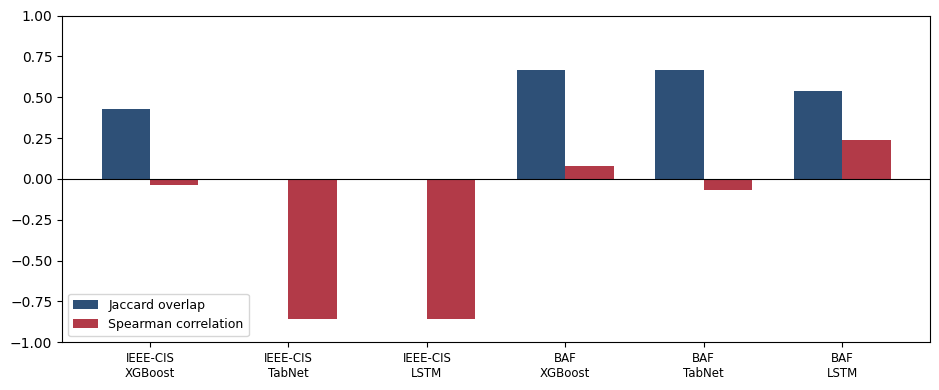

In [ ]:
fig, ax = plt.subplots(figsize=(9.5, 4))
x = np.arange(len(agreement_summary))
width = 0.35

ax.bar(x - width/2, agreement_summary["shap_lime_jaccard"], width, label="Jaccard overlap", color="#2E5077")
ax.bar(x + width/2, agreement_summary["shap_lime_spearman"], width, label="Spearman correlation", color="#B23A48")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels([f"{r.dataset}\n{r.model}" for r in agreement_summary.itertuples()], fontsize=8.5)
ax.set_ylim(-1, 1)
ax.legend(fontsize=9, loc="lower left")
plt.tight_layout()
plt.savefig("shap_lime_agreement_chart.png", dpi=200, bbox_inches="tight")
plt.show()

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

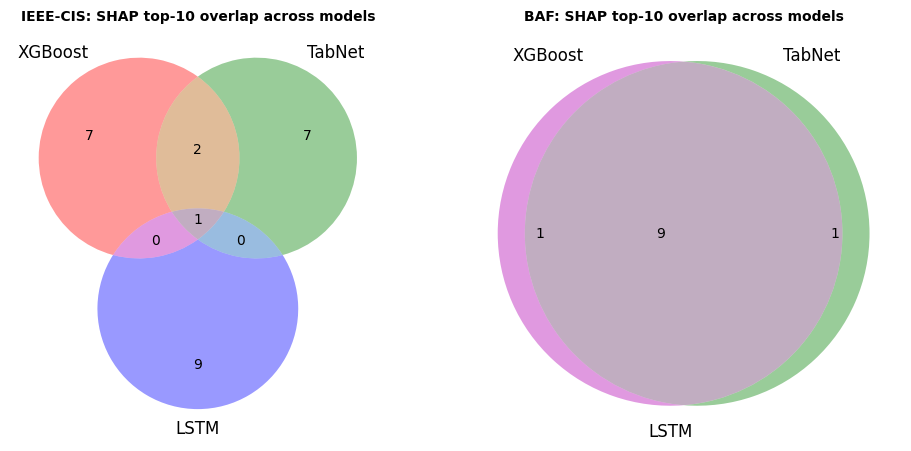

In [ ]:
from matplotlib_venn import venn3
import matplotlib.pyplot as plt

# ---- IEEE-CIS: SHAP top-10 sets for all three models ----
ieee_sets = [
    set(shap_top_xgb_ieee),
    set(top_k_features_from_shap(
        get_shap_values_generic(lambda x: tabnet_ieee.predict_proba(x)[:, 1], ieee_data["X_nn"],
        ieee_data["train_idx"], ieee_data["test_idx"])[0], ieee_data["feature_names"])),
    set(top_k_features_from_shap(
        get_shap_values_generic(lambda x: lstm_predict_proba_1col(lstm_ieee, x),
        ieee_data["X_nn"], ieee_data["train_idx"], ieee_data["test_idx"])[0], ieee_data["feature_names"])),
]

# ---- BAF: SHAP top-10 sets for all three models ----
baf_sets = [
    set(shap_top_xgb_baf),
    set(top_k_features_from_shap(
        get_shap_values_generic(lambda x: tabnet_baf.predict_proba(x)[:, 1], baf_data["X_nn"],
        baf_data["train_idx"], baf_data["test_idx"])[0], baf_data["feature_names"])),
    set(top_k_features_from_shap(
        get_shap_values_generic(lambda x: lstm_predict_proba_1col(lstm_baf, x),
        baf_data["X_nn"], baf_data["train_idx"], baf_data["test_idx"])[0], baf_data["feature_names"])),
]

# ---- Plot both side by side ----
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))

venn3(ieee_sets, set_labels=("XGBoost", "TabNet", "LSTM"), ax=axes[0])
axes[0].set_title("IEEE-CIS: SHAP top-10 overlap across models", fontsize=10, fontweight="bold")

venn3(baf_sets, set_labels=("XGBoost", "TabNet", "LSTM"), ax=axes[1])
axes[1].set_title("BAF: SHAP top-10 overlap across models", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.savefig("shap_venn_diagrams.png", dpi=200, bbox_inches="tight")
plt.show()